# Virtual worms and entropy triangles

This notebook reconstructs the virtual-worm workflow from the project codebase.

The steps are:

1. Load one concentration from the compiled `.mat` file.
2. Build virtual worms from the experimental traces.
3. Turn the traces into continuous and binary formal contexts.
4. Compute SMET and CMET tables across all available `phi` values.
5. Visualize the four standard triangles.

All reusable logic lives in `src/`. The notebook only orchestrates the pipeline.


In [1]:

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpltern  # registers the ternary projection
from IPython.display import display

BASE_DIR = Path("..").resolve()
SRC_DIR = BASE_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from calculate_entropies import sentropies, jentropies, build_smet_from_intents, build_smet_from_extents
from fca import compute_concepts, build_extents_intents_all_worms
from utils import (
    load_compiled_data,
    build_odor_neuron_structs,
    build_virtual_worm_traces,
    build_random_virtual_worms,
    compute_formal_contexts_from_traces,
    binarize_contexts,
)
from visualize_triangles import (
    plot_smet_triangle,
    plot_smet_interactive,
    plot_cmet_triangle,
    plot_cmet_interactive,
)


## Configuration

Set the concentration and the sampling mode here.

- `concentration`: `4`, `5`, or `6`
- `random_worms`: `True` uses random sampling with a fixed seed
- `selected_phi`: reference `phi` used for the static four-panel figure


In [2]:

concentration = 4
semiring = "minplus"
random_worms = True
window_seconds = 2.0
seed = 42


In [3]:

mat_path = BASE_DIR / "contexts" / f"compiled_data_conc_{concentration}.mat"
context_dir = BASE_DIR / "contexts" / f"od_by_neuron{concentration}_23x11_{semiring}"

data = load_compiled_data(mat_path)

ap_time = data["ap_time"]
compiled_LR_ordered = data["compiled_LR_ordered"]
neuron_names = data["neuron_names"]
odor_names = data["odor_names"]
Ns = data["Ns"]
min_samples = data["min_samples"]

sorted_context_files = sorted(
    [p for p in context_dir.glob("*.csv")],
    key=lambda p: float(p.stem.split("_")[-1]),
)

summary_df = pd.DataFrame(
    {
        "item": ["concentration", "n_odors", "n_neurons", "min_samples", "n_context_files"],
        "value": [concentration, len(odor_names), len(neuron_names), min_samples, len(sorted_context_files)],
    }
)
display(summary_df)
# To save this table, write it to BASE_DIR / "results" / f"virtual_worms_summary_1e-{concentration}.csv".


,item,value
0,concentration,4
1,n_odors,23
2,n_neurons,11
3,min_samples,18
4,n_context_files,158


## Build the virtual worms

The project uses the same construction already tested in the original notebooks.


In [5]:

odor_neuron_structs, neuron_name_to_idx = build_odor_neuron_structs(
    compiled_LR_ordered,
    neuron_names,
)

if random_worms:
    virtual_traces = build_random_virtual_worms(
        odor_neuron_structs,
        neuron_name_to_idx,
        ap_time,
        n_worms=min_samples,
        seed=seed,
        store_indices=False,
    )
else:
    virtual_traces = build_virtual_worm_traces(
        odor_neuron_structs,
        neuron_name_to_idx,
        ap_time,
        min_samples=min_samples,
    )

contexts_cont = compute_formal_contexts_from_traces(
    virtual_traces,
    ap_time,
    window_seconds=window_seconds,
)

virtual_summary_df = pd.DataFrame(
    {
        "item": ["virtual_traces_shape", "contexts_cont_shape"],
        "value": [str(virtual_traces.shape), str(contexts_cont.shape)],
    }
)
display(virtual_summary_df)
# To save this table, write it to BASE_DIR / "results" / f"virtual_worms_shapes_1e-{concentration}.csv".


,item,value
0,virtual_traces_shape,"(18, 23, 11, 96)"
1,contexts_cont_shape,"(18, 23, 11)"


## SMET for neurons across all `phi` values

This block reproduces the neuron-side SMET table using concept intents.


In [6]:

SEDF_allphis_list = []

for path in sorted_context_files:
    phi_val = float(path.stem.split("_")[-1])

    contexts_bin_phi = binarize_contexts(
        contexts_cont,
        phi=phi_val,
        mode=">=",
    )

    SEDF_phi = build_smet_from_intents(
        contexts_bin_phi,
        odor_names=odor_names,
        neuron_names=neuron_names,
        phi=phi_val,
    )
    SEDF_allphis_list.append(SEDF_phi)

SEDF_allphis = pd.concat(SEDF_allphis_list, ignore_index=True)
display(SEDF_allphis.head())
# To save this table, write it to BASE_DIR / "results" / f"SEDF_allphis_{100 + concentration}.csv".


,name,H_Uxi,H_Pxi,DeltaH_Pxi,M_Pxi,VI_Pxi,DeltaH_norm,M_norm,VI_norm,worm,phi
0,ADF,1.0,-0.0,1.0,-0.0,0.0,1.0,-0.0,0.0,1,-0.416584
1,ADL,1.0,-0.0,1.0,-0.0,0.0,1.0,-0.0,0.0,1,-0.416584
2,ASE,1.0,-0.0,1.0,-0.0,0.0,1.0,-0.0,0.0,1,-0.416584
3,ASG,1.0,-0.0,1.0,-0.0,0.0,1.0,-0.0,0.0,1,-0.416584
4,ASH,1.0,-0.0,1.0,-0.0,0.0,1.0,-0.0,0.0,1,-0.416584


## SMET for odorants across all `phi` values

This is the odor-side SMET table built from concept extents.


In [7]:

SEDF_allphis_odor_list = []

for path in sorted_context_files:
    phi_val = float(path.stem.split("_")[-1])

    contexts_bin_phi = binarize_contexts(
        contexts_cont,
        phi=phi_val,
        mode=">=",
    )

    SEDF_phi = build_smet_from_extents(
        contexts_bin_phi,
        odor_names=odor_names,
        neuron_names=neuron_names,
        phi=phi_val,
    )
    SEDF_allphis_odor_list.append(SEDF_phi)

SEDF_allphis_odor = pd.concat(SEDF_allphis_odor_list, ignore_index=True)
display(SEDF_allphis_odor.head())
# To save this table, write it to BASE_DIR / "results" / f"SEDF_allphis_odor_{100 + concentration}.csv".


,name,H_Uxi,H_Pxi,DeltaH_Pxi,M_Pxi,VI_Pxi,DeltaH_norm,M_norm,VI_norm,worm,phi
0,1-pentanol,1.0,0.918296,0.081704,0.918296,0.0,0.081704,0.918296,0.0,1,-0.416584
1,1-hexanol,1.0,-0.000000,1.000000,-0.000000,0.0,1.000000,-0.000000,0.0,1,-0.416584
2,1-heptanol,1.0,-0.000000,1.000000,-0.000000,0.0,1.000000,-0.000000,0.0,1,-0.416584
3,1-octanol,1.0,-0.000000,1.000000,-0.000000,0.0,1.000000,-0.000000,0.0,1,-0.416584
4,1-nonanol,1.0,-0.000000,1.000000,-0.000000,0.0,1.000000,-0.000000,0.0,1,-0.416584


## CMET across all `phi` values

The channel table is computed from the extents and intents concatenated across worms.


In [8]:

CMET_list = []

for path in sorted_context_files:
    phi_val = float(path.stem.split("_")[-1])

    contexts_bin_phi = binarize_contexts(
        contexts_cont,
        phi=phi_val,
        mode=">=",
    )

    ext_all, int_all = build_extents_intents_all_worms(
        contexts_bin_phi,
        odor_names=odor_names,
        neuron_names=neuron_names,
    )

    cmet_phi = jentropies(ext_all, int_all)
    cmet_phi["phi"] = phi_val
    CMET_list.append(cmet_phi)

CMET_all_phi = pd.concat(CMET_list, ignore_index=True)
display(CMET_all_phi.head())
# To save this table, write it to BASE_DIR / "results" / f"CMET_all_phi_{100 + concentration}.csv".


,type,H_U,H_P,DeltaH_P,M_P,VI_P,DeltaH_norm,I_norm,Hcond_norm,phi
0,X,22.0,3.091917,18.908083,1.691704,1.400213,0.859458,0.076896,0.063646,-0.416584
1,Y,4.0,2.788094,1.211906,1.691704,1.096390,0.302976,0.422926,0.274098,-0.416584
2,XY,26.0,5.880011,20.119989,3.383408,2.496603,0.773846,0.130131,0.096023,-0.416584
3,X,23.0,3.350444,19.649556,1.839380,1.511064,0.854329,0.079973,0.065698,-0.394146
4,Y,5.0,3.068719,1.931281,1.839380,1.229339,0.386256,0.367876,0.245868,-0.394146


## Static four-panel view

This figure shows the four standard triangles across the full `phi` sweep for the selected concentration.

Each panel is generated from the same family of plotting functions, with only the dataframe and the triangle type changing. The goal is to display the full trajectory, not a single threshold snapshot.

### Parameters used in the plotting calls

- `df`: dataframe containing the values to plot. In this notebook, each panel receives the dataframe corresponding to one entropy representation.
- `mode`: only used in SMET plots. It controls how the dataframe is filtered before plotting:
  - `global_avg`: plots the pooled `@AVERAGE` trajectory across all virtual worms,
  - `per_worm_avg`: plots one average trajectory per worm,
  - `one_worm_all`: plots all rows for a selected worm.
- `typ`: only used in CMET plots. It selects which channel side is drawn:
  - `X`: source-side channel decomposition,
  - `Y`: destination-side channel decomposition,
  - `XY`: joint channel representation, when available.
- `phi_val`: if a numeric value is given, the plot is restricted to that single threshold. Here it is set to `None` so that the whole `phi` sweep can be displayed.
- `accumulate`: if `True`, all points up to the selected `phi` are shown. In this static figure it is used together with `phi_val=None`, so the complete trajectory is drawn.
- `interactive`: enables or disables widget-based interaction. It is set to `False` here because this is a static figure.
- `title`: title shown above each panel.
- `ax`: target ternary axis where the panel is drawn. This is what allows the four plots to be placed in a single figure.
- `fixed_phi_range`: if `True`, the color scale is forced to use the same `phi` range across panels. This makes the colors directly comparable.
- `phi_min`, `phi_max`: lower and upper bounds of the shared color scale.
- `add_colorbar`: controls whether each subplot adds its own colorbar. It is set to `False` here to keep the layout compact.
- `show_trajectory`: if `True`, a black trajectory is overlaid to make the path across `phi` easier to follow.


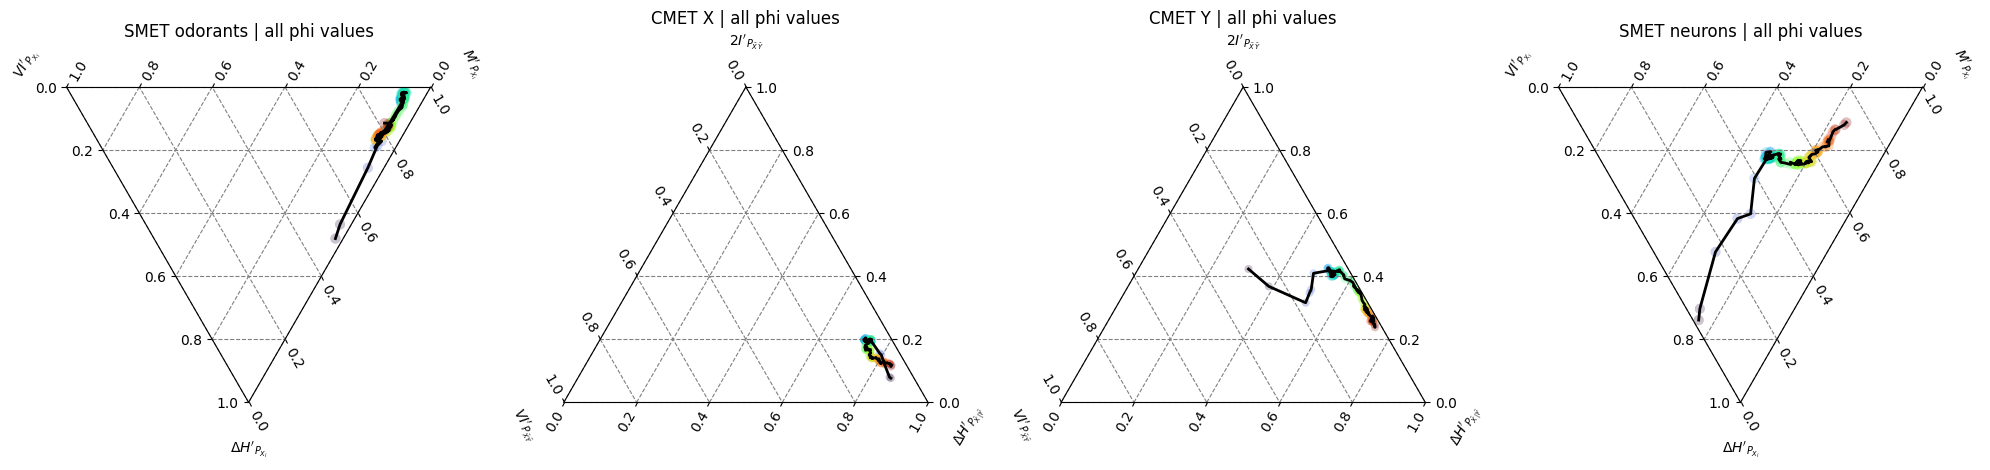

In [14]:
phi_values = np.sort(SEDF_allphis["phi"].astype(float).unique())

fig = plt.figure(figsize=(20, 5.5))

ax1 = fig.add_subplot(1, 4, 1, projection="ternary", rotation=180)
plot_smet_triangle(
    df=SEDF_allphis_odor,
    mode="global_avg",
    phi_val=None,
    accumulate=True,
    interactive=False,
    title="SMET odorants | all phi values",
    ax=ax1,
    fixed_phi_range=True,
    phi_min=phi_values.min(),
    phi_max=phi_values.max(),
    add_colorbar=False,
    show_trajectory=True,
)

ax2 = fig.add_subplot(1, 4, 2, projection="ternary")
plot_cmet_triangle(
    df=CMET_all_phi,
    typ="X",
    phi_val=None,
    accumulate=True,
    interactive=False,
    title="CMET X | all phi values",
    ax=ax2,
    fixed_phi_range=True,
    phi_min=phi_values.min(),
    phi_max=phi_values.max(),
    add_colorbar=False,
    show_trajectory=True,
)

ax3 = fig.add_subplot(1, 4, 3, projection="ternary")
plot_cmet_triangle(
    df=CMET_all_phi,
    typ="Y",
    phi_val=None,
    accumulate=True,
    interactive=False,
    title="CMET Y | all phi values",
    ax=ax3,
    fixed_phi_range=True,
    phi_min=phi_values.min(),
    phi_max=phi_values.max(),
    add_colorbar=False,
    show_trajectory=True,
)

ax4 = fig.add_subplot(1, 4, 4, projection="ternary", rotation=180)
plot_smet_triangle(
    df=SEDF_allphis,
    mode="global_avg",
    phi_val=None,
    accumulate=True,
    interactive=False,
    title="SMET neurons | all phi values",
    ax=ax4,
    fixed_phi_range=True,
    phi_min=phi_values.min(),
    phi_max=phi_values.max(),
    add_colorbar=False,
    show_trajectory=True,
)

plt.tight_layout()
plt.show()
# To save this figure, use fig.savefig(BASE_DIR / "figures" / f"all_triang_{concentration}.png", dpi=300, bbox_inches="tight").

## Interactive viewers and display options

The SMET plotting functions support three display modes:

- `global_avg`: plots only the `@AVERAGE` row pooled across all virtual worms. This is the cleanest view to follow the global trajectory across `phi`.
- `per_worm_avg`: plots one `@AVERAGE` trajectory per virtual worm. This is useful to compare worm-to-worm variability while keeping the representation compact.
- `one_worm_all`: plots all individual entries for a single virtual worm. This is the most detailed view and can optionally be restricted to one or several names.

For CMET, the main distinction is not the aggregation mode but the channel side being plotted:

- `X`: source-side channel decomposition
- `Y`: destination-side channel decomposition
- `XY`: joint channel representation, when available in the dataframe



The `accumulate` option changes the temporal interpretation of the slider:
- if `True`, all points up to the selected `phi` are shown,
- if `False`, only the exact selected `phi` is shown.

In [10]:

plot_smet_interactive(
    df=SEDF_allphis,
    phi_values=sorted(SEDF_allphis["phi"].unique()),
    mode="global_avg",
    title="SMET neurons",
)
# To save one view from this widget, reproduce the same parameters in a static plotting cell and save the resulting figure in BASE_DIR / "figures".


interactive(children=(IntSlider(value=0, description='φ index', max=157), Checkbox(value=True, description='Ac…

In [11]:

plot_smet_interactive(
    df=SEDF_allphis_odor,
    phi_values=sorted(SEDF_allphis_odor["phi"].unique()),
    mode="global_avg",
    title="SMET odorants",
)
# To save one view from this widget, reproduce the same parameters in a static plotting cell and save the resulting figure in BASE_DIR / "figures".


interactive(children=(IntSlider(value=0, description='φ index', max=157), Checkbox(value=True, description='Ac…

In [12]:

plot_cmet_interactive(
    df=CMET_all_phi,
    phi_values=sorted(CMET_all_phi["phi"].unique()),
)
# To save one view from this widget, reproduce the same parameters in a static plotting cell and save the resulting figure in BASE_DIR / "figures".


interactive(children=(IntSlider(value=0, description='φ index', max=157), Checkbox(value=True, description='Ac…